# Matched-context pretraining-risk scaling with training-bank size

Forced-linear **parameter estimation** only. Existing caches, two seeds, training and test contexts n = 2, 8, 32, 128. No model loading, training, or inference.

The measured quantity is population pretraining risk estimated on independent held-out tasks: normalized all-token parameter MSE. This is **not empirical training loss**, and these are **not frozen-model inference-context scaling curves**.

The theorem bounds excess over the context-specific Bayes risk by approximation/statistical-construction terms, a complexity term of order P log(e+cM)/M, and optimization error. At fixed n the Bayes risk is constant in M. Thus fitting total risk to F + A(M/M0)^(-beta) can identify a decaying component without computing posterior means; F combines Bayes risk and persistent excess error. It does not identify either separately or prove the theorem tight. The all-token interpretation uses the same Bayes predictor at every token.

The actual experiments use a practical fixed architecture and validation-selected checkpoints, not certified approximate global empirical minimizers in the theorem's constrained class. Thirty fixed epochs means more optimization steps at larger M. Any exponent is therefore descriptive of this training protocol. Low n may also fall outside the theorem's sample-size assumptions.

Plots use equal-weight averages across the two trained seeds (errors, not predictions). Test-error bands are within-seed bootstrap intervals for this average, conditional on the trained models, not across-training-seed confidence intervals. Original figure filenames are retained.


In [9]:
from pathlib import Path
import json, hashlib, csv
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
while not (ROOT/'src'/'ode_paper').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT/'src'/'ode_paper').is_dir():
    raise RuntimeError('Run from Paper repo or its notebooks directory.')
OUT = ROOT/'figures'/'pretraining_risk_scaling'
OUT.mkdir(parents=True, exist_ok=True)
NS = (2, 8, 32, 128)
SEEDS = (20260906, 20260907)
MS = np.array([2**k for k in (11, 13, 15, 17, 19)], dtype=float)
M0 = MS[0]
BETA_BOUNDS = (0.02, 5.0)  # Boundary hits signal weak identification/model inadequacy.
BOOTSTRAPS = 200  # Conditional test-bank bootstrap, NOT training-seed uncertainty.
RNG = np.random.default_rng(4812026)
import sys
sys.path.insert(0, str(ROOT/'src'))
from ode_paper.paper_style import apply_style
apply_style()

def table(records):
    keys = list(records[0])
    def fmt(v): return f'{v:.5g}' if isinstance(v, (float, np.floating)) else str(v)
    display(Markdown('| '+' | '.join(keys)+' |\n| '+ ' | '.join(['---']*len(keys))+' |\n'+
                     '\n'.join('| '+' | '.join(fmt(r[k]) for k in keys)+' |' for r in records)))

def savefig(fig, name):
    fig.tight_layout()
    for ext in ('png','pdf'): fig.savefig(OUT/f'{name}.{ext}', dpi=170, bbox_inches='tight')
    plt.show()

def savecsv(name, records):
    with (OUT/name).open('w', newline='') as f:
        w=csv.DictWriter(f, fieldnames=list(records[0])); w.writeheader(); w.writerows(records)


## Cache and protocol checks
Read only the selected evaluations, verify exported checksums and identities, reconstruct L_all from per-coordinate errors, and verify equal targets across M within each seed/context. Bootstrap resampling preserves this within-bank pairing. Seeds have different test banks and are resampled independently. Exported training manifests are checked for identical settings except M, n, and seeds.

In [10]:
losses, provenance, configs = {}, [], []
for seed in SEEDS:
    base = ROOT/'evaluation_cache_downloads'/f'seed_{seed}'
    cat = json.loads((base/'catalog.json').read_text())
    assert cat['seed'] == seed and cat['format_version'] == 1
    for n in NS:
        columns=[]; reference=None
        for M in MS.astype(int):
            matches=[e for e in cat['evaluations'] if e['group']=='main_experiment'
                     and e['config']['family']=='forced_linear' and e['config']['task']=='parameter'
                     and e['config']['n']==n and e['inference_n']==n and e['config']['M']==M]
            assert len(matches)==1, (seed,n,M,len(matches))
            e=matches[0]; cache=base/e['cache']; run=base/e['run']
            for p in (cache/'metrics.json', cache/'per_example.npz', run/'manifest.json'):
                rel=p.relative_to(base).as_posix()
                assert hashlib.sha256(p.read_bytes()).hexdigest()==cat['sha256'][rel], p
            rec=json.loads((cache/'metrics.json').read_text())
            manifest=json.loads((run/'manifest.json').read_text())
            cfg=e['config']; configs.append(cfg)
            assert rec['identity']['config']==cfg==manifest['spec']['config']
            assert cfg['seed']==cfg['data_seed']==seed and cfg['epochs']==30
            assert rec['identity']['n']==n and 1<=rec['best_epoch']<=30
            with np.load(cache/'per_example.npz', allow_pickle=False) as z:
                error=z['all_token_coordinate_mse'].astype(float).mean(axis=1)
                targets=z['targets'].copy()
            assert len(error)==8192 and np.isfinite(error).all() and (error>=0).all()
            if reference is None: reference=targets
            else: assert np.array_equal(reference,targets), 'Test tasks differ across M'
            assert np.isclose(error.mean(),rec['metrics']['all_token_mse'],rtol=1e-7)
            columns.append(error)
            provenance.append(dict(n=n,M=M,seed=seed,risk=error.mean(),test_SE=error.std(ddof=1)/np.sqrt(len(error)),
                                   best_epoch=rec['best_epoch'],updates=manifest['updates'],parameters=manifest['parameters'],
                                   checkpoint=rec['identity']['checkpoint_sha256'],cache=str(cache.relative_to(ROOT))))
        losses[n,seed]=np.stack(columns,axis=1)
omit={'M','n','seed','data_seed'}
assert all({k:v for k,v in c.items() if k not in omit}=={k:v for k,v in configs[0].items() if k not in omit} for c in configs)
assert len({r['parameters'] for r in provenance})==1
Y={n:np.stack([losses[n,s].mean(axis=0) for s in SEEDS]) for n in NS}
savecsv('cache_audit.csv',provenance)
print('Verified',len(provenance),'evaluations; 8192 examples each. No training or inference performed.')
table([{k:r[k] for k in ('n','M','seed','risk','best_epoch','updates')} for r in provenance])


Verified 40 evaluations; 8192 examples each. No training or inference performed.


| n | M | seed | risk | best_epoch | updates |
| --- | --- | --- | --- | --- | --- |
| 2 | 2048 | 20260906 | 0.10363 | 30 | 240 |
| 2 | 8192 | 20260906 | 0.081892 | 29 | 960 |
| 2 | 32768 | 20260906 | 0.075102 | 30 | 3840 |
| 2 | 131072 | 20260906 | 0.072833 | 24 | 15360 |
| 2 | 524288 | 20260906 | 0.072187 | 22 | 61440 |
| 8 | 2048 | 20260906 | 0.039857 | 30 | 240 |
| 8 | 8192 | 20260906 | 0.012463 | 26 | 960 |
| 8 | 32768 | 20260906 | 0.00465 | 28 | 3840 |
| 8 | 131072 | 20260906 | 0.0024421 | 24 | 15360 |
| 8 | 524288 | 20260906 | 0.0023516 | 15 | 61440 |
| 32 | 2048 | 20260906 | 0.013053 | 30 | 240 |
| 32 | 8192 | 20260906 | 0.0034393 | 27 | 960 |
| 32 | 32768 | 20260906 | 0.0010541 | 26 | 3840 |
| 32 | 131072 | 20260906 | 0.00070102 | 12 | 15360 |
| 32 | 524288 | 20260906 | 0.00075443 | 9 | 61440 |
| 128 | 2048 | 20260906 | 0.0072515 | 30 | 240 |
| 128 | 8192 | 20260906 | 0.0019207 | 27 | 960 |
| 128 | 32768 | 20260906 | 0.00080276 | 25 | 3840 |
| 128 | 131072 | 20260906 | 0.0003312 | 14 | 15360 |
| 128 | 524288 | 20260906 | 0.00033111 | 6 | 61440 |
| 2 | 2048 | 20260907 | 0.1029 | 30 | 240 |
| 2 | 8192 | 20260907 | 0.080436 | 28 | 960 |
| 2 | 32768 | 20260907 | 0.07379 | 27 | 3840 |
| 2 | 131072 | 20260907 | 0.071517 | 27 | 15360 |
| 2 | 524288 | 20260907 | 0.07064 | 23 | 61440 |
| 8 | 2048 | 20260907 | 0.049614 | 30 | 240 |
| 8 | 8192 | 20260907 | 0.015907 | 30 | 960 |
| 8 | 32768 | 20260907 | 0.0044235 | 30 | 3840 |
| 8 | 131072 | 20260907 | 0.0019675 | 25 | 15360 |
| 8 | 524288 | 20260907 | 0.0022476 | 8 | 61440 |
| 32 | 2048 | 20260907 | 0.014154 | 29 | 240 |
| 32 | 8192 | 20260907 | 0.0029874 | 25 | 960 |
| 32 | 32768 | 20260907 | 0.00071731 | 26 | 3840 |
| 32 | 131072 | 20260907 | 0.0003364 | 23 | 15360 |
| 32 | 524288 | 20260907 | 0.00046757 | 4 | 61440 |
| 128 | 2048 | 20260907 | 0.0099416 | 27 | 240 |
| 128 | 8192 | 20260907 | 0.0018877 | 25 | 960 |
| 128 | 32768 | 20260907 | 0.00062301 | 23 | 3840 |
| 128 | 131072 | 20260907 | 0.00016147 | 27 | 15360 |
| 128 | 524288 | 20260907 | 0.0002516 | 11 | 61440 |

## Fit definitions
The primary fit minimizes equally weighted squared **log-risk** residuals across both seeds. The original-scale least-squares fit is a sensitivity check. No inverse-test-SE weighting is used: it would ignore variation from training.

Constraints: F,A >= 0 and 0.02 <= beta <= 5. Parameters F,A are rescaled by the largest observed risk for numerical conditioning; M is rescaled by M0. Multiple initializations are tried. Compare free beta with beta=1, and an illustrative log(e+M)/M curve with a free floor and amplitude. The latter fixes the otherwise unknown logarithmic constant and is **not the literal theoretical bound**. Lower fitting error for the three-parameter model is expected; held-out errors are more informative.

The observed-risk plot shows the arithmetic mean across seeds. The shared fitting objective and seed-specific numerical sensitivity checks remain unchanged; seed-specific checks are retained in tables rather than drawn as separate performance curves.


| n | model | F | beta | log_RMSE | beta_boundary |
| --- | --- | --- | --- | --- | --- |
| 2 | free | 0.071163 | 0.83526 | 0.0086638 | False |
| 2 | beta1 | 0.072033 | 1 | 0.012493 | False |
| 2 | log1 | 0.071474 | 1 | 0.0090582 | False |
| 2 | raw | 0.071175 | 0.83663 | 0.0086643 | False |
| 8 | free | 0.0019082 | 1.0237 | 0.13102 | False |
| 8 | beta1 | 0.0018683 | 1 | 0.13183 | False |
| 8 | log1 | 0.001679 | 1 | 0.15569 | False |
| 8 | raw | 0.0014825 | 0.90219 | 0.16445 | False |
| 32 | free | 0.00049801 | 1.2663 | 0.24486 | False |
| 32 | beta1 | 0.0004211 | 1 | 0.29181 | False |
| 32 | log1 | 0.00038182 | 1 | 0.33775 | False |
| 32 | raw | 0.00045711 | 1.1416 | 0.25696 | False |
| 128 | free | 0.00022901 | 1.1238 | 0.25486 | False |
| 128 | beta1 | 0.00020357 | 1 | 0.26871 | False |
| 128 | log1 | 0.00017893 | 1 | 0.3045 | False |
| 128 | raw | 0.00026815 | 1.1589 | 0.26585 | False |

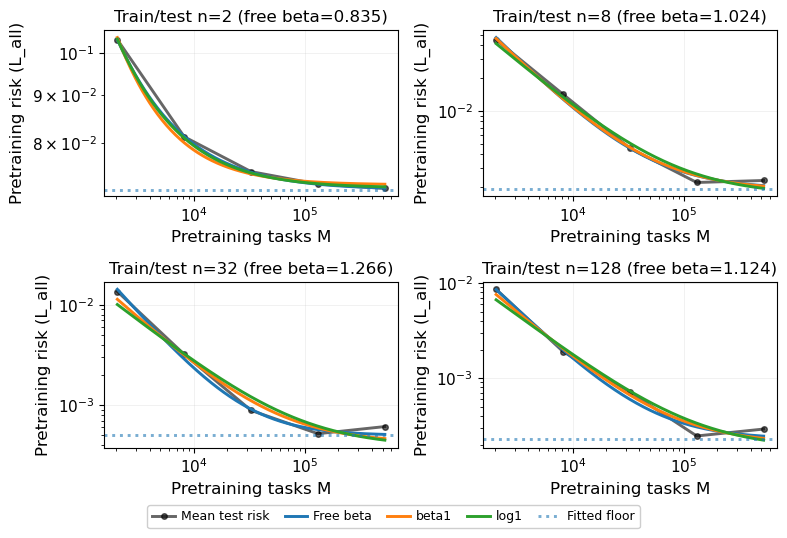

In [11]:
def basis(m,beta,kind):
    m=np.asarray(m,float)
    if kind=='log1': return (np.log(np.e+m)/m)/(np.log(np.e+M0)/M0)
    return (m/M0)**(-beta)

def fit(m,y,scale='log',fixed=None,kind='power',starts=(.1,.5,1.,2.,4.)):
    m=np.asarray(m,float); y=np.asarray(y,float)
    if y.ndim==1: y=y[None,:]
    assert (y>0).all()
    unit=float(y.max()); z=y/unit
    free=fixed is None and kind=='power'
    def residual(p):
        beta=p[2] if free else (1. if fixed is None else fixed)
        pred=p[0]+p[1]*basis(m,beta,kind)
        if scale=='log': return (np.log(np.maximum(pred,1e-300))[None,:]-np.log(z)).ravel()
        return (pred[None,:]-z).ravel()
    best=None
    for b in (starts if free else (1.,)):
        for fraction in (0.,.8):
            p=[fraction*z.min(), max(z.max()-fraction*z.min(),1e-6)]
            if free: p.append(np.clip(b,*BETA_BOUNDS))
            lo=[0,0]+([BETA_BOUNDS[0]] if free else [])
            hi=[np.inf,np.inf]+([BETA_BOUNDS[1]] if free else [])
            res=least_squares(residual,p,bounds=(lo,hi),max_nfev=1500,ftol=1e-10,xtol=1e-10,gtol=1e-10)
            if res.success and (best is None or np.sum(res.fun**2)<np.sum(best.fun**2)): best=res
    if best is None: raise RuntimeError('Fit failed')
    beta=float(best.x[2]) if free else float(fixed if fixed is not None else 1.)
    return dict(F=float(best.x[0]*unit),A=float(best.x[1]*unit),beta=beta,kind=kind,
                objective=float(np.sum(best.fun**2)),scale=scale,
                beta_boundary=bool(free and (beta<BETA_BOUNDS[0]+.001 or beta>BETA_BOUNDS[1]-.001)))

def predict(f,m): return f['F']+f['A']*basis(m,f['beta'],f['kind'])
fits={}; summary=[]
for n in NS:
    for name,kwargs in [('free',{}),('beta1',{'fixed':1.}),('log1',{'kind':'log1'}),('raw',{'scale':'raw'})]:
        f=fit(MS,Y[n],**kwargs); fits[n,name]=f
        summary.append(dict(n=n,model=name,**f,log_RMSE=float(np.sqrt(np.mean((np.log(predict(f,MS))[None,:]-np.log(Y[n]))**2)))))
savecsv('fits.csv',summary)
table([{k:r[k] for k in ('n','model','F','beta','log_RMSE','beta_boundary')} for r in summary])
fig,axs=plt.subplots(2,2,figsize=(8,5.2))
grid=np.geomspace(MS.min(),MS.max(),300)
for ax,n in zip(axs.flat,NS):
    ax.loglog(MS,Y[n].mean(axis=0), 'o-',color='black',alpha=.6,label='Mean test risk')
    for name,color in [('free','tab:blue'),('beta1','tab:orange'),('log1','tab:green')]:
        f=fits[n,name]; label='Free beta' if name=='free' else name
        ax.loglog(grid,predict(f,grid),color=color,label=label)
    ax.axhline(fits[n,'free']['F'],color='tab:blue',ls=':',alpha=.6,label='Fitted floor')
    ax.set(title=f'Train/test n={n} (free beta={fits[n,"free"]["beta"]:.3f})',xlabel='Pretraining tasks M',ylabel='Pretraining risk (L_all)')
    ax.grid(alpha=.2)
# One shared legend beneath all four panels, placed just below the bottom x-axis labels.
handles,labels=axs.flat[0].get_legend_handles_labels()
fig.tight_layout(); fig.canvas.draw()
below=min(ax.get_tightbbox().transformed(fig.transFigure.inverted()).y0 for ax in axs[-1])
fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,below-.004),ncol=len(labels),fontsize=9,
           handlelength=1.8,columnspacing=1.2,handletextpad=.5,framealpha=.95)
savefig(fig,'matched_pretraining_risk_fits')


## Exponent profile (descriptive, not a confidence interval)
For each fixed beta, refit the floor and amplitude. A broad, shallow minimum means the exponent is weakly identified. The objective includes seed disagreement; no likelihood-ratio confidence threshold is asserted.

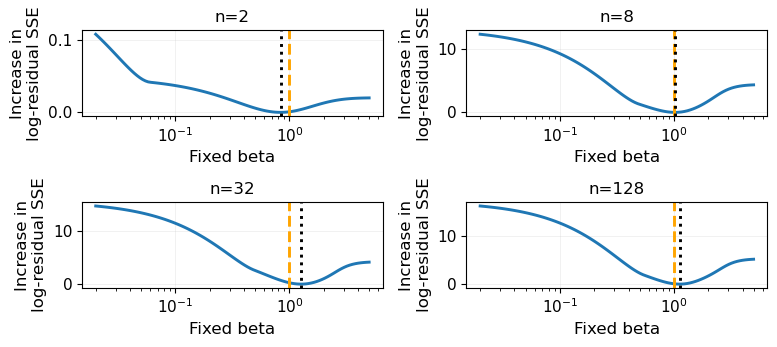

In [12]:
profiles=[]
betas=np.unique(np.r_[np.geomspace(.02,5,100),1.])
fig,axs=plt.subplots(2,2,figsize=(8,3.6))
for ax,n in zip(axs.flat,NS):
    for b in betas:
        f=fit(MS,Y[n],fixed=b)
        profiles.append(dict(n=n,beta=b,F=f['F'],objective=f['objective']))
    vals=np.array([r['objective'] for r in profiles if r['n']==n])
    ax.semilogx(betas,vals-fits[n,'free']['objective'])
    ax.axvline(1,color='orange',ls='--'); ax.axvline(fits[n,'free']['beta'],color='black',ls=':')
    ax.set(title=f'n={n}',xlabel='Fixed beta',ylabel='Increase in\nlog-residual SSE'); ax.grid(alpha=.2)
savecsv('exponent_profiles.csv',profiles)
savefig(fig,'exponent_profiles')


## Seed, fitting-range, and prediction checks
Fit seeds separately, drop the smallest M, and refit on the original scale. For extrapolation, fit the four smaller sizes and predict the largest. Leave-one-size-out checks remove both seeds at a size together. These errors are predictions of total pretraining risk, not of Bayes excess risk.

| n | check | beta | F | beta_boundary |
| --- | --- | --- | --- | --- |
| 2 | all_log | 0.83526 | 0.071163 | False |
| 2 | drop_smallest | 0.78327 | 0.071018 | False |
| 2 | original_scale | 0.83663 | 0.071175 | False |
| 2 | seed_20260906 | 0.82952 | 0.071862 | False |
| 2 | seed_20260907 | 0.84095 | 0.070471 | False |
| 8 | all_log | 1.0237 | 0.0019082 | False |
| 8 | drop_smallest | 1.2336 | 0.0020623 | False |
| 8 | original_scale | 0.90219 | 0.0014825 | False |
| 8 | seed_20260906 | 0.98272 | 0.0020362 | False |
| 8 | seed_20260907 | 1.067 | 0.001792 | False |
| 32 | all_log | 1.2663 | 0.00049801 | False |
| 32 | drop_smallest | 1.5709 | 0.00052697 | False |
| 32 | original_scale | 1.1416 | 0.00045711 | False |
| 32 | seed_20260906 | 1.2014 | 0.00066984 | False |
| 32 | seed_20260907 | 1.3356 | 0.00037057 | False |
| 128 | all_log | 1.1238 | 0.00022901 | False |
| 128 | drop_smallest | 1.1452 | 0.00023099 | False |
| 128 | original_scale | 1.1589 | 0.00026815 | False |
| 128 | seed_20260906 | 0.99884 | 0.00027849 | False |
| 128 | seed_20260907 | 1.2417 | 0.00018579 | False |

Largest M withheld (relative_error is signed):


| n | model | held_M | predicted | observed | relative_error | log_RMSE | fitted_beta |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 2 | free | 524288 | 0.071561 | 0.071414 | 0.0020668 | 0.011037 | 0.84276 |
| 2 | beta1 | 524288 | 0.072503 | 0.071414 | 0.015251 | 0.01866 | 1 |
| 2 | log1 | 524288 | 0.071828 | 0.071414 | 0.0058045 | 0.012308 | 1 |
| 8 | free | 524288 | 0.0014663 | 0.0022996 | -0.36236 | 0.45029 | 0.91392 |
| 8 | beta1 | 524288 | 0.0016968 | 0.0022996 | -0.26215 | 0.3046 | 1 |
| 8 | log1 | 524288 | 0.0014046 | 0.0022996 | -0.38919 | 0.49322 | 1 |
| 32 | free | 524288 | 0.0003919 | 0.000611 | -0.35859 | 0.47965 | 1.1621 |
| 32 | beta1 | 524288 | 0.00031342 | 0.000611 | -0.48704 | 0.68251 | 1 |
| 32 | log1 | 524288 | 0.00025161 | 0.000611 | -0.5882 | 0.89157 | 1 |
| 128 | free | 524288 | 0.00013125 | 0.00029136 | -0.54953 | 0.79993 | 0.96495 |
| 128 | beta1 | 524288 | 0.00014464 | 0.00029136 | -0.50356 | 0.7044 | 1 |
| 128 | log1 | 524288 | 0.00010189 | 0.00029136 | -0.65028 | 1.0502 | 1 |

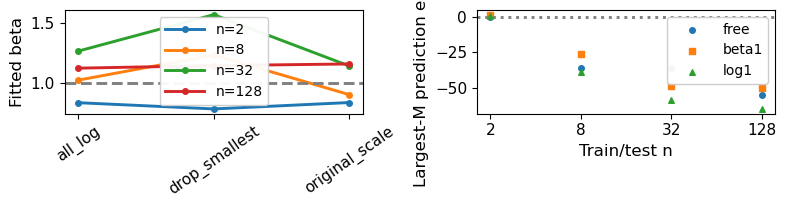

In [13]:
checks=[]; holdouts=[]
for n in NS:
    for label,m,y,kw in [('all_log',MS,Y[n],{}),('drop_smallest',MS[1:],Y[n][:,1:],{}),
                         ('original_scale',MS,Y[n],{'scale':'raw'})]+[(f'seed_{s}',MS,Y[n][j],{}) for j,s in enumerate(SEEDS)]:
        f=fit(m,y,**kw)
        checks.append(dict(n=n,check=label,beta=f['beta'],F=f['F'],beta_boundary=f['beta_boundary']))
    for name,kw in [('free',{}),('beta1',{'fixed':1.}),('log1',{'kind':'log1'})]:
        for j in range(len(MS)):
            keep=np.arange(len(MS))!=j
            f=fit(MS[keep],Y[n][:,keep],**kw)
            pred=float(predict(f,MS[j])); observed=float(Y[n][:,j].mean())
            holdouts.append(dict(n=n,model=name,held_M=int(MS[j]),predicted=pred,observed=observed,
                                 relative_error=pred/observed-1,log_RMSE=float(np.sqrt(np.mean((np.log(pred)-np.log(Y[n][:,j]))**2))),
                                 fitted_beta=f['beta']))
savecsv('sensitivity_checks.csv',checks); savecsv('held_out_predictions.csv',holdouts)
table(checks)
print('Largest M withheld (relative_error is signed):')
table([r for r in holdouts if r['held_M']==int(MS[-1])])
fig,axs=plt.subplots(1,2,figsize=(8,2.25))
for n in NS:
    rr=[r for r in checks if r['n']==n and not r['check'].startswith('seed_')]
    axs[0].plot([r['check'] for r in rr],[r['beta'] for r in rr],'o-',label=f'n={n}')
    for j,name in enumerate(('free','beta1','log1')):
        r=next(r for r in holdouts if r['n']==n and r['model']==name and r['held_M']==MS[-1])
        axs[1].scatter(str(n),100*r['relative_error'],marker=['o','s','^'][j],color=['tab:blue','tab:orange','tab:green'][j],label=name if n==NS[0] else None)
axs[0].axhline(1,color='gray',ls='--'); axs[0].set_ylabel('Fitted beta'); axs[0].tick_params(axis='x',rotation=35); axs[0].legend()
axs[1].axhline(0,color='gray',ls=':'); axs[1].set(xlabel='Train/test n',ylabel='Largest-M prediction error (%)'); axs[1].legend()
savefig(fig,'sensitivity_and_largest_M_holdout')


## Conditional test-bank bootstrap
Resample 8192 test tasks with replacement independently within each seed, using the same resampled indices across M; refit the joint curve. These percentile intervals quantify **only finite-test-bank uncertainty conditional on these two trained sweeps**. They are not confidence intervals for a universal exponent, nor do they capture new training datasets/initializations. Seed-specific fits above are essential. With only two seeds, a training-seed bootstrap would be poorly resolved and is deliberately not presented as reliable inference.

In [14]:
boot=[]; boot_summary=[]
for n in NS:
    for b in range(BOOTSTRAPS):
        yy=np.stack([losses[n,s][RNG.integers(0,len(losses[n,s]),len(losses[n,s]))].mean(axis=0) for s in SEEDS])
        f=fit(MS,yy,starts=(fits[n,'free']['beta'],))
        boot.append(dict(n=n,replicate=b,beta=f['beta'],F=f['F']))
    vals=np.array([r['beta'] for r in boot if r['n']==n])
    lo,hi=np.quantile(vals,[.025,.975])
    boot_summary.append(dict(n=n,beta=fits[n,'free']['beta'],conditional_test_only_low=lo,conditional_test_only_high=hi))
savecsv('conditional_test_bootstrap.csv',boot); savecsv('conditional_test_bootstrap_summary.csv',boot_summary)
table(boot_summary)


| n | beta | conditional_test_only_low | conditional_test_only_high |
| --- | --- | --- | --- |
| 2 | 0.83526 | 0.79816 | 0.87461 |
| 8 | 1.0237 | 1.0042 | 1.0429 |
| 32 | 1.2663 | 1.2525 | 1.2823 |
| 128 | 1.1238 | 1.1113 | 1.1338 |

## Interpretation and scope
* A beta near one is descriptive consistency with a power-decaying pretraining-risk component, not verification of an upper bound's tightness.
* A non-unit beta does not contradict the theorem: its finite-M term is logarithm-corrected, and approximation/optimization terms need not be negligible or constant along a practical training protocol.
* The floor is unidentified as Bayes versus persistent excess risk. Subtracting a fitted floor cannot independently validate that same fit.
* Context n is held fixed in each fit. Comparing these four panels does not estimate a frozen-model inference-n exponent, nor does it establish a 1/n excess-risk rate.
* Profile width, seed disagreement, fitting-range sensitivity, and held-out prediction are more informative than a high in-sample fit score.
* This notebook never modifies caches/checkpoints. All tables and figures are saved under figures/pretraining_risk_scaling.


In [15]:
report={'scope':'forced_linear parameter; matched train/test n; total normalized all-token pretraining risk',
        'seeds':list(SEEDS),'M':MS.astype(int).tolist(),'n':list(NS),'bootstrap_replicates':BOOTSTRAPS,
        'fits':summary,'sensitivity':checks,'held_out':holdouts,'conditional_test_bootstrap':boot_summary}
(OUT/'results.json').write_text(json.dumps(report,indent=2))
print('Saved all results to',OUT)


Saved all results to <repo>/figures/pretraining_risk_scaling


In [16]:
# Numerical sanity checks on the fitting implementation.
for beta in (.4, 1., 1.7):
    synthetic=.002+.04*(MS/M0)**(-beta)
    recovered=fit(MS,synthetic)
    assert np.isclose(recovered['beta'],beta,rtol=1e-4), recovered
    assert np.allclose(predict(recovered,MS),synthetic,rtol=1e-5)
assert all(fits[n,'free']['objective'] <= fits[n,'beta1']['objective']+1e-8 for n in NS)
print('Synthetic recovery and nested-objective checks passed.')

takeaways=[]
for n in NS:
    seed_betas=[r['beta'] for r in checks if r['n']==n and r['check'].startswith('seed_')]
    h=next(r for r in holdouts if r['n']==n and r['model']=='free' and r['held_M']==int(MS[-1]))
    takeaways.append(dict(n=n,pooled_beta=fits[n,'free']['beta'],
                          seed_beta_min=min(seed_betas),seed_beta_max=max(seed_betas),
                          largest_M_holdout_error_percent=100*h['relative_error']))
table(takeaways)
display(Markdown("""### Takeaway from the cached runs
The fitted exponents are of order one, but this is **not a precise verification of a 1/M excess-pretraining-risk rate**. For n=8,32,128 the largest-M risk is underpredicted appreciably when that size is withheld. Several seed curves flatten or rise at the largest size, which a strictly decreasing floor-plus-power model cannot reproduce. The n=2 curve is smoother and the exponent is consistent between seeds, but its substantial floor makes accuracy in total risk a weaker test of the small decaying component.

For n=8, fixing beta=1 gives almost the same in-sample log error as fitting beta freely. The n=32 exponent is more sensitive to excluding the smallest size. Seed-specific fits and the original-scale fit also differ. Narrow conditional test-bootstrap intervals do not remove these model and training uncertainties.

The defensible conclusion is that increasing the number of pretraining tasks produces substantial decreases in held-out pretraining risk followed by flattening, with an effective decay exponent roughly of order one over this grid. The data do not establish an exact exponent or identify Bayes excess risk. The theorem is an upper bound with a logarithmic finite-M term, approximation terms, and optimization error, not a statement that risk equals a single power law. Comparing n panels does not separately verify a 1/n exponent.
"""))


Synthetic recovery and nested-objective checks passed.


| n | pooled_beta | seed_beta_min | seed_beta_max | largest_M_holdout_error_percent |
| --- | --- | --- | --- | --- |
| 2 | 0.83526 | 0.82952 | 0.84095 | 0.20668 |
| 8 | 1.0237 | 0.98272 | 1.067 | -36.236 |
| 32 | 1.2663 | 1.2014 | 1.3356 | -35.859 |
| 128 | 1.1238 | 0.99884 | 1.2417 | -54.953 |

### Takeaway from the cached runs
The fitted exponents are of order one, but this is **not a precise verification of a 1/M excess-pretraining-risk rate**. For n=8,32,128 the largest-M risk is underpredicted appreciably when that size is withheld. Several seed curves flatten or rise at the largest size, which a strictly decreasing floor-plus-power model cannot reproduce. The n=2 curve is smoother and the exponent is consistent between seeds, but its substantial floor makes accuracy in total risk a weaker test of the small decaying component.

For n=8, fixing beta=1 gives almost the same in-sample log error as fitting beta freely. The n=32 exponent is more sensitive to excluding the smallest size. Seed-specific fits and the original-scale fit also differ. Narrow conditional test-bootstrap intervals do not remove these model and training uncertainties.

The defensible conclusion is that increasing the number of pretraining tasks produces substantial decreases in held-out pretraining risk followed by flattening, with an effective decay exponent roughly of order one over this grid. The data do not establish an exact exponent or identify Bayes excess risk. The theorem is an upper bound with a logarithmic finite-M term, approximation terms, and optimization error, not a statement that risk equals a single power law. Comparing n panels does not separately verify a 1/n exponent.
